# Resting-State Functional Network Topology and Fluid Intelligence
### A graph-theoretic analysis pipeline for Human Connectome Project (HCP) data

**Question.** Is the topology of a person's resting-state functional brain network (how clustered, segregated and efficiently connected it is) related to their fluid intelligence score?

**Pipeline.**
1. Load parcellated resting-state fMRI time series (100 nodes per subject) and behavioural scores
2. Build a functional connectivity matrix per subject (Pearson correlation via `nilearn.connectome.ConnectivityMeasure`)
3. Threshold each matrix into a sparse graph and compute graph metrics with `networkx`: clustering coefficient, characteristic path length, global efficiency, modularity, small-worldness, hubs
4. Relate each network metric to a behavioural score (Pearson and Spearman correlation, permutation test, Bonferroni correction)
5. Check that the result holds across graph densities

> ⚠️ **PLACEHOLDER DATA NOTICE**
> HCP data requires a signed Data Use Agreement, so **this notebook runs on simulated data by default** (`USE_SYNTHETIC = True`). The simulated data has the same shape as the HCP release (subjects × timepoints × 100 nodes, plus a behavioural table) and a deliberately **planted** brain-behaviour effect so the pipeline has something to detect. **None of the numbers below are findings about real brains.** Section 1 explains how to get the real data, and Section 2 shows the one-line switch.

## 1. Getting the real HCP data (do this yourself, about 15 minutes)

HCP Young Adult (S1200) data is free but gated behind a Data Use Agreement. You have to accept it personally; it cannot be done on your behalf.

1. Go to **https://www.humanconnectome.org** → *Data* → *ConnectomeDB* (HCP Young Adult) and create a free account.
2. Log in and accept the **WU-Minn HCP Consortium Open Access Data Use Terms**. (The *Restricted* terms, needed for age-in-years, family structure etc., are a separate application and are **not** needed here.)
3. In the **WU-Minn HCP Data – 1200 Subjects** project, download:
   * **"HCP1200 Parcellation + Timeseries + Netmats (PTN)"**: the group-ICA node time series. Inside the archive, extract the `d100` (100-node) MSMAll time series. You should end up with a folder of one text file per subject, e.g. `node_timeseries/3T_HCP1200_MSMAll_d100_ts2/100206.txt`. Each file is a plain-text matrix of *timepoints × 100 nodes* (4 resting-state runs × 1200 volumes concatenated).
   * **Behavioral Data (unrestricted CSV)**: a spreadsheet with one row per subject and a `Subject` column.
4. Put them in `data/` next to this notebook (or edit the paths in the config cell):
   ```
   data/
     node_timeseries/3T_HCP1200_MSMAll_d100_ts2/*.txt
     unrestricted_behavioral.csv
   ```
5. Set `USE_SYNTHETIC = False` and re-run all cells.

**Verify before relying on it:** ConnectomeDB's menus, file names and archive layout have changed over the years. If a name above doesn't match what you see, trust the HCP S1200 Reference Manual and data dictionary over this notebook. The default behavioural column `PMAT24_A_CR` (Penn Progressive Matrices, number correct; a standard fluid-intelligence measure) should be checked against the data dictionary too.

**Never commit HCP data to GitHub.** The Data Use Terms forbid redistribution. `data/` is in `.gitignore`.

## 2. Configuration

In [1]:
# ---------------------------------------------------------------
# SWITCH: True = simulated placeholder data, False = real HCP data
# ---------------------------------------------------------------
USE_SYNTHETIC = True

from pathlib import Path

# Real-data paths (used only when USE_SYNTHETIC = False)
HCP_TS_DIR        = Path("data/node_timeseries/3T_HCP1200_MSMAll_d100_ts2")
HCP_BEHAVIOR_CSV  = Path("data/unrestricted_behavioral.csv")
BEHAVIOR_COLUMN   = "PMAT24_A_CR"   # fluid intelligence; verify in the HCP data dictionary

N_SUBJECTS   = 100     # subset size (50-100 keeps runtime to a few minutes)
DENSITY      = 0.10    # keep the strongest 10% of edges in each graph
DENSITIES    = [0.05, 0.10, 0.15, 0.20]  # robustness sweep
N_PERM       = 5000    # permutations for the brain-behaviour test
SEED         = 42

# Primary metric for the headline plot, fixed BEFORE looking at results (avoids cherry-picking).
# Global efficiency = network integration; van den Heuvel et al. (2009, J Neurosci) linked
# shorter path length / higher efficiency to higher IQ.
PRIMARY_METRIC = "global_eff"

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

In [2]:
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from nilearn.connectome import ConnectivityMeasure
from nilearn import plotting

warnings.filterwarnings("ignore", category=FutureWarning)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
import nilearn; print("nilearn", nilearn.__version__, "| networkx", nx.__version__, "| pandas", pd.__version__)

nilearn 0.14.1 | networkx 3.7 | pandas 3.1.1


## 3. Data

### 3a. Simulated placeholder data
The generator mimics the *shape* and some coarse *structure* of HCP resting-state data:

* 100 nodes grouped into 7 "networks" (roughly the number of canonical resting-state networks), each driven by a shared slow latent signal, plus a weak global signal and node-specific autocorrelated noise.
* Each subject has a hidden **segregation** parameter controlling how strongly nodes follow their own network's signal. Higher segregation gives more modular, more clustered graphs.
* The behavioural score is generated from that hidden parameter plus noise: subjects with *less* segregated (more integrated) networks get higher scores, with a true correlation of −0.35 between segregation and score. Scores are scaled to the 0–24 range of the Penn Matrix Test. The direction was chosen to match the integration hypothesis in Section 6; it is a simulation setting, not evidence for that hypothesis.

So the brain-behaviour link in this notebook is **planted by construction**. Its purpose is to check that the pipeline can recover a known effect, not to make a claim about brains.

In [3]:
def simulate_hcp_like(n_subjects=100, n_timepoints=1200, n_nodes=100, n_networks=7,
                      true_r=0.35, seed=0):
    # Return (list of [T x N] time series, behaviour DataFrame, node->network labels).
    # PLACEHOLDER: synthetic data only.
    r = np.random.default_rng(seed)
    sizes = r.multinomial(n_nodes - 6 * n_networks, np.ones(n_networks) / n_networks) + 6
    labels = np.repeat(np.arange(n_networks), sizes)               # unequal network sizes
    system = np.arange(n_networks) % 2                             # 2 meta-systems linking networks
    second = r.integers(0, n_networks, n_nodes)                    # ~30% "connector" nodes
    conn_w = np.where((r.random(n_nodes) < 0.3) & (second != labels), r.uniform(0.4, 0.8, n_nodes), 0)

    def ar1(shape, phi):                                           # unit-variance AR(1) noise
        x = r.standard_normal(shape)
        for t in range(1, shape[0]):
            x[t] += phi * x[t - 1]
        return x * np.sqrt(1 - phi**2)

    segregation = r.normal(1.0, 0.25, n_subjects).clip(0.4, 1.6)  # hidden subject trait
    ts_list = []
    for s in range(n_subjects):
        latent = ar1((n_timepoints, n_networks), 0.9)              # one slow signal per network
        latent = latent + 0.5 * ar1((n_timepoints, 2), 0.9)[:, system]
        glob = ar1((n_timepoints, 1), 0.9)
        noise = ar1((n_timepoints, n_nodes), 0.5) * 2.5
        load = segregation[s] * r.uniform(0.5, 1.5, n_nodes)
        x = latent[:, labels] * load + latent[:, second] * conn_w + 0.8 * glob + noise
        ts_list.append((x - x.mean(0)) / x.std(0))

    z = (segregation - segregation.mean()) / segregation.std()
    # planted effect: LESS segregation (= more integration) -> higher score
    beh = -true_r * z + np.sqrt(1 - true_r**2) * r.standard_normal(n_subjects)
    pmat = np.clip(np.round(17 + 4 * beh), 0, 24)                  # PMAT24-like 0-24 scale
    behaviour = pd.DataFrame({"Subject": [f"SIM{100000 + i}" for i in range(n_subjects)],
                              "score": pmat})
    return ts_list, behaviour, labels

### 3b. Real HCP loader
Used when `USE_SYNTHETIC = False`. It reads the PTN node-time-series text files, matches them to the behavioural CSV by subject ID, drops subjects missing the score, and takes the first `N_SUBJECTS`.

In [4]:
def load_hcp_ptn(ts_dir, behavior_csv, behavior_col, n_subjects=100):
    beh = pd.read_csv(behavior_csv)
    beh["Subject"] = beh["Subject"].astype(str)
    beh = beh[["Subject", behavior_col]].dropna().rename(columns={behavior_col: "score"})
    files = {p.stem: p for p in sorted(Path(ts_dir).glob("*.txt"))}
    subs = [s for s in beh["Subject"] if s in files][:n_subjects]
    if not subs:
        raise FileNotFoundError(f"No subjects matched between {ts_dir} and {behavior_csv}")
    ts_list = [np.loadtxt(files[s]) for s in subs]
    beh = beh.set_index("Subject").loc[subs].reset_index()
    labels = None   # ICA nodes have no network labels; we derive communities from the data
    print(f"Loaded {len(subs)} HCP subjects; time series shape {ts_list[0].shape}")
    return ts_list, beh, labels

In [5]:
if USE_SYNTHETIC:
    print("⚠️  Using SIMULATED placeholder data. Results are NOT real findings.")
    ts_list, behaviour, node_labels = simulate_hcp_like(n_subjects=N_SUBJECTS, seed=SEED)
else:
    ts_list, behaviour, node_labels = load_hcp_ptn(HCP_TS_DIR, HCP_BEHAVIOR_CSV,
                                                   BEHAVIOR_COLUMN, N_SUBJECTS)

n_sub, (n_tp, n_nodes) = len(ts_list), ts_list[0].shape
print(f"{n_sub} subjects | {n_tp} timepoints | {n_nodes} nodes")
behaviour.describe().round(2)

⚠️  Using SIMULATED placeholder data. Results are NOT real findings.


100 subjects | 1200 timepoints | 100 nodes


,score
count,100.00
mean,17.09
std,3.82
min,8.00
25%,14.75
50%,17.00
75%,20.00
max,24.00


## 4. Functional connectivity matrices
For each subject, connectivity is the Pearson correlation between every pair of node time series (100 × 100). Correlations are Fisher-*z* transformed before averaging across subjects, then transformed back.

In [6]:
conn = ConnectivityMeasure(kind="correlation", vectorize=False, discard_diagonal=False)
fc = conn.fit_transform(ts_list)                 # (subjects, nodes, nodes)
np.einsum("sii->si", fc)[:] = 0                  # zero the diagonal
fc_z = np.arctanh(np.clip(fc, -0.999999, 0.999999))
group_fc = np.tanh(fc_z.mean(0))
print("FC array:", fc.shape, "| mean off-diagonal r =", round(group_fc[np.triu_indices(n_nodes, 1)].mean(), 3))

FC array: (100, 100, 100) | mean off-diagonal r = 0.113


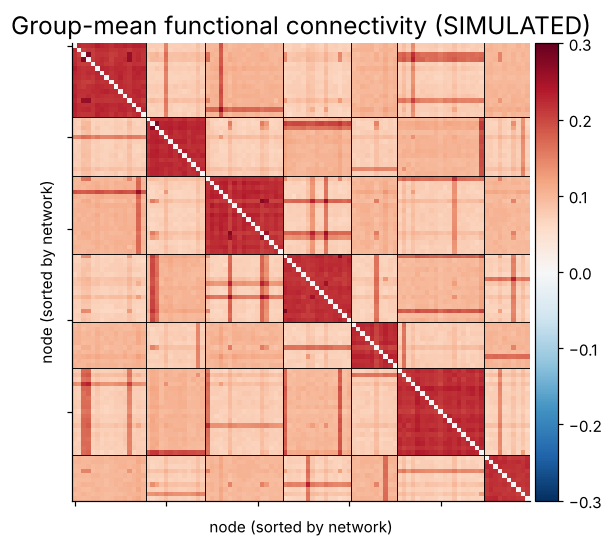

In [7]:
# Order nodes by network (simulated labels) or by data-driven communities (real data)
def communities_of(mat, density):
    G = threshold_graph(mat, density)
    comms = nx.community.greedy_modularity_communities(G)
    lab = np.empty(mat.shape[0], int)
    for k, c in enumerate(comms):
        lab[list(c)] = k
    return lab

def threshold_graph(mat, density):
    # Binary undirected graph with exactly `density` x (possible edges) edges:
    # a maximum-spanning-tree backbone (guarantees one connected component) plus the
    # strongest remaining correlations, added in descending order.
    n = mat.shape[0]
    iu = np.triu_indices(n, 1)
    w = mat[iu]
    k = int(round(density * len(w)))
    full = nx.Graph()
    full.add_weighted_edges_from((i, j, 1 - mat[i, j]) for i, j in zip(*iu))  # distance = 1 - r
    G = nx.Graph(nx.minimum_spanning_tree(full).edges())
    for idx in np.argsort(w)[::-1]:
        if G.number_of_edges() >= k:
            break
        G.add_edge(iu[0][idx], iu[1][idx])
    return G

order_labels = node_labels if node_labels is not None else communities_of(group_fc, DENSITY)
order = np.argsort(order_labels, kind="stable")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
vmax = np.ceil(np.abs(group_fc[np.triu_indices(n_nodes, 1)]).max() * 20) / 20   # round up to 0.05
plotting.plot_matrix(group_fc[np.ix_(order, order)], vmin=-vmax, vmax=vmax, cmap="RdBu_r",
                     colorbar=True, axes=ax,
                     title="Group-mean functional connectivity" + (" (SIMULATED)" if USE_SYNTHETIC else ""))
bounds = np.flatnonzero(np.diff(order_labels[order])) + 0.5
for b in bounds:
    ax.axhline(b, color="k", lw=0.6); ax.axvline(b, color="k", lw=0.6)
ax.set_xlabel("node (sorted by network)"); ax.set_ylabel("node (sorted by network)")
fig.savefig(FIG_DIR / "connectivity_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()

## 5. Graph construction and graph-theoretic metrics

Each subject's matrix becomes a **binary, undirected graph** with exactly 10% of possible edges (*proportional thresholding*). Every subject then has the same number of edges, so differences in topology aren't simply differences in how many connections survived.

Plain "keep the top 10%" thresholding often splits a brain graph into disconnected pieces, which makes path length undefined for some node pairs. So the graph is built from a **minimum spanning tree** of the distance matrix (1 − r), which links every node through its strongest available connections, and the strongest remaining edges are then added until the density target is reached. This MST-plus-threshold approach is a common choice in the connectomics literature.

| Metric | What it captures | NetworkX |
|---|---|---|
| Clustering coefficient | how often a node's neighbours are connected to each other (local segregation) | `average_clustering` |
| Characteristic path length | average shortest path between nodes (integration) | `average_shortest_path_length` |
| Global efficiency | mean inverse shortest path; handles disconnected nodes | `global_efficiency` |
| Modularity *Q* | how well the graph splits into dense communities | `community.modularity` |
| Small-worldness σ | (C/C_rand)/(L/L_rand) against degree-preserving random graphs | `double_edge_swap` |
| Hubs | nodes with top degree *and* betweenness centrality | `degree`, `betweenness_centrality` |

In [8]:
def graph_metrics(G):
    giant = G.subgraph(max(nx.connected_components(G), key=len))
    comms = nx.community.greedy_modularity_communities(G)
    return {
        "clustering":   nx.average_clustering(G),
        "path_length":  nx.average_shortest_path_length(giant),
        "global_eff":   nx.global_efficiency(G),
        "modularity":   nx.community.modularity(G, comms),
        "giant_frac":   giant.number_of_nodes() / G.number_of_nodes(),
    }

def metrics_at_density(fc, density):
    rows = [graph_metrics(threshold_graph(m, density)) for m in fc]
    return pd.DataFrame(rows)

metrics = metrics_at_density(fc, DENSITY)
metrics.insert(0, "Subject", behaviour["Subject"].values)
metrics["score"] = behaviour["score"].values
metrics.describe().round(3)

,clustering,path_length,global_eff,modularity,giant_frac,score
count,100.000,100.000,100.000,100.000,100.0,100.000
mean,0.600,3.153,0.404,0.576,1.0,17.090
std,0.136,0.662,0.041,0.130,0.0,3.817
min,0.264,2.351,0.290,0.277,1.0,8.000
25%,0.536,2.742,0.382,0.508,1.0,14.750
50%,0.631,3.018,0.407,0.598,1.0,17.000
75%,0.694,3.406,0.431,0.669,1.0,20.000
max,0.827,5.875,0.480,0.800,1.0,24.000


### Small-worldness of the group graph
Compare the group graph against degree-preserving randomised versions (Maslov–Sneppen edge swaps). σ > 1 means the graph is more clustered than random while keeping comparably short paths, which is the classic "small-world" signature reported for brain networks.

In [9]:
G_group = threshold_graph(group_fc, DENSITY)

def random_reference(G, n_ref=20, swaps_per_edge=10, seed=SEED):
    C, L = [], []
    for i in range(n_ref):
        R = G.copy()
        nx.double_edge_swap(R, nswap=swaps_per_edge * R.number_of_edges(),
                            max_tries=10**6, seed=seed + i)
        giant = R.subgraph(max(nx.connected_components(R), key=len))
        C.append(nx.average_clustering(R)); L.append(nx.average_shortest_path_length(giant))
    return np.mean(C), np.mean(L)

giant = G_group.subgraph(max(nx.connected_components(G_group), key=len))
C_obs, L_obs = nx.average_clustering(G_group), nx.average_shortest_path_length(giant)
C_rnd, L_rnd = random_reference(G_group)
sigma = (C_obs / C_rnd) / (L_obs / L_rnd)
print(f"C = {C_obs:.3f} (random {C_rnd:.3f}) | L = {L_obs:.3f} (random {L_rnd:.3f}) | sigma = {sigma:.2f}")

C = 0.809 (random 0.113) | L = 4.646 (random 2.253) | sigma = 3.46


### Hub detection
A hub here is a node in the top 10% of the group graph for **both** degree and betweenness centrality. Using two criteria avoids labelling a node a hub just because it sits inside one large, dense community.

In [10]:
deg = pd.Series(dict(G_group.degree()))
btw = pd.Series(nx.betweenness_centrality(G_group))
hub_df = pd.DataFrame({"degree": deg, "betweenness": btw.round(4), "network": order_labels})
hub_mask = (deg >= deg.quantile(0.9)) & (btw >= btw.quantile(0.9))
hubs = hub_df[hub_mask].sort_values("betweenness", ascending=False)
print(f"{len(hubs)} hub nodes (top 10% degree AND betweenness):")
hubs

4 hub nodes (top 10% degree AND betweenness):


,degree,betweenness,network
42,15,0.2657,2
83,15,0.2433,5
32,15,0.2211,1
14,15,0.2045,0


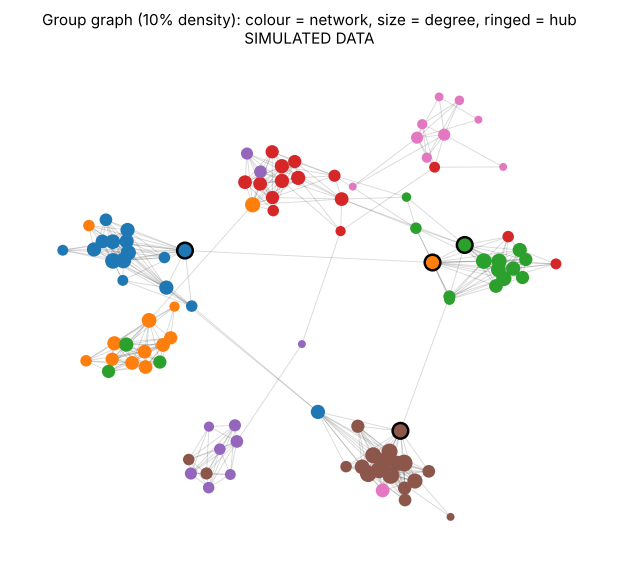

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
pos = nx.spring_layout(G_group, seed=SEED, k=0.35)
cmap = plt.get_cmap("tab10")
nx.draw_networkx_edges(G_group, pos, ax=ax, alpha=0.15, width=0.6)
nx.draw_networkx_nodes(G_group, pos, ax=ax, node_size=[15 + 6 * d for d in deg.values],
                       node_color=[cmap(l % 10) for l in order_labels], linewidths=0)
nx.draw_networkx_nodes(G_group, pos, nodelist=list(hubs.index), ax=ax, node_size=[15 + 6 * deg[h] for h in hubs.index],
                       node_color="none", edgecolors="k", linewidths=1.6)
ax.set_title("Group graph (10% density): colour = network, size = degree, ringed = hub" +
             ("\nSIMULATED DATA" if USE_SYNTHETIC else ""), fontsize=10)
ax.axis("off")
fig.savefig(FIG_DIR / "group_graph_hubs.png", bbox_inches="tight", dpi=150)
plt.show()

## 6. Brain–behaviour relationship
Each of the four main metrics is correlated with the behavioural score across subjects:

* **Pearson r** with a **permutation p-value** (shuffle scores 5,000 times; no normality assumption)
* **Spearman ρ** as a rank-based check that one or two subjects aren't driving the result
* **Bonferroni correction** for testing 4 metrics (α = 0.05 / 4 = 0.0125)

The scatter plot shows the **pre-specified primary metric** (`PRIMARY_METRIC`, global efficiency), not whichever metric happened to give the smallest p-value. The other three are reported in the table as secondary results.

In [12]:
def perm_test(x, y, n_perm=N_PERM, seed=SEED):
    r_obs = stats.pearsonr(x, y)[0]
    r = np.random.default_rng(seed)
    null = np.array([stats.pearsonr(x, r.permutation(y))[0] for _ in range(n_perm)])
    return r_obs, (np.sum(np.abs(null) >= abs(r_obs)) + 1) / (n_perm + 1)

METRICS = ["clustering", "path_length", "global_eff", "modularity"]
rows = []
for m in METRICS:
    r, p_perm = perm_test(metrics[m].values, metrics["score"].values)
    rho, p_rho = stats.spearmanr(metrics[m], metrics["score"])
    rows.append({"metric": m, "pearson_r": r, "p_perm": p_perm,
                 "p_bonferroni": min(1, p_perm * len(METRICS)), "spearman_rho": rho, "p_spearman": p_rho})
results = pd.DataFrame(rows).set_index("metric")
results.round(4)

,pearson_r,p_perm,p_bonferroni,spearman_rho,p_spearman
metric,,,,,
clustering,-0.3691,0.0002,0.0008,-0.3622,0.0002
path_length,-0.3107,0.0020,0.0080,-0.4016,0.0000
global_eff,0.3614,0.0004,0.0016,0.3990,0.0000
modularity,-0.3629,0.0004,0.0016,-0.3541,0.0003


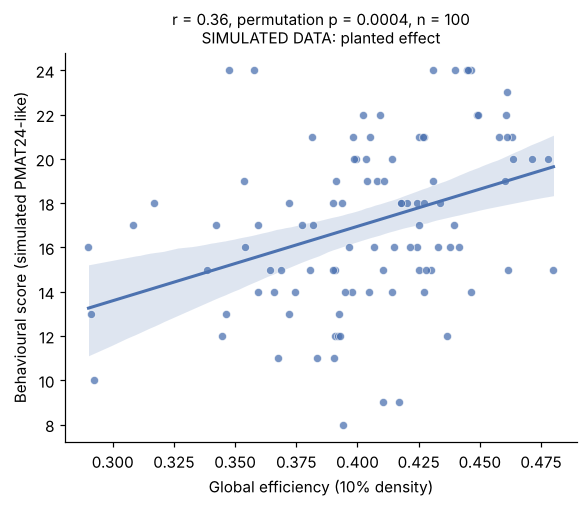

In [13]:
best = PRIMARY_METRIC   # pre-specified in the config cell, not chosen by smallest p
pretty = {"clustering": "Mean clustering coefficient", "path_length": "Characteristic path length",
          "global_eff": "Global efficiency", "modularity": "Modularity Q"}
x, y = metrics[best].values, metrics["score"].values
slope, intercept = np.polyfit(x, y, 1)

# bootstrap 95% CI band for the regression line
xs = np.linspace(x.min(), x.max(), 100)
boot = np.empty((1000, xs.size)); r_ = np.random.default_rng(SEED)
for b in range(1000):
    i = r_.integers(0, len(x), len(x)); s_, i_ = np.polyfit(x[i], y[i], 1); boot[b] = s_ * xs + i_
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(6, 4.6))
ax.fill_between(xs, lo, hi, color="#4C72B0", alpha=0.18, lw=0)
ax.plot(xs, slope * xs + intercept, color="#4C72B0", lw=2)
ax.scatter(x, y, s=28, color="#4C72B0", alpha=0.75, edgecolor="white", linewidth=0.5)
rr = results.loc[best]
ax.set_xlabel(f"{pretty[best]} (10% density)")
ax.set_ylabel("Fluid intelligence (PMAT24 correct)" if not USE_SYNTHETIC else "Behavioural score (simulated PMAT24-like)")
ax.set_title(f"r = {rr.pearson_r:.2f}, permutation p = {rr.p_perm:.4f}, n = {len(x)}" +
             ("\nSIMULATED DATA: planted effect" if USE_SYNTHETIC else ""), fontsize=10)
fig.savefig(FIG_DIR / "brain_behavior_scatter.png", bbox_inches="tight", dpi=150)
plt.show()

## 7. Robustness across graph densities
A result that appears at only one arbitrary threshold is fragile. The same correlations are recomputed at 5%, 10%, 15% and 20% density.

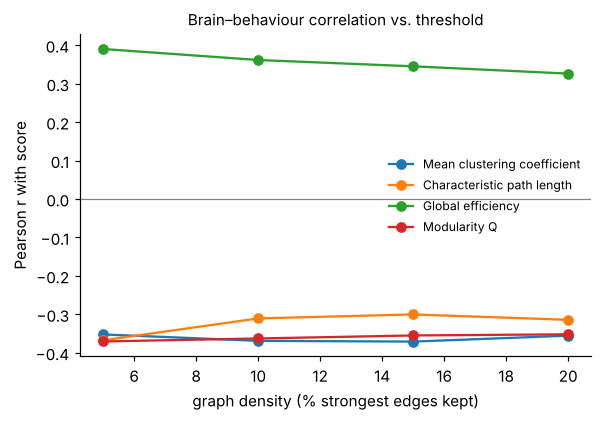

density,0.05,0.10,0.15,0.20
metric,,,,
clustering,-0.352,-0.369,-0.371,-0.356
global_eff,0.390,0.361,0.345,0.326
modularity,-0.371,-0.363,-0.355,-0.352
path_length,-0.368,-0.311,-0.300,-0.314


In [14]:
sweep = []
for d in DENSITIES:
    md_ = metrics_at_density(fc, d)
    for m in METRICS:
        r, p = stats.pearsonr(md_[m], behaviour["score"])
        sweep.append({"density": d, "metric": m, "r": r, "p": p})
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(6, 3.8))
for m in METRICS:
    s = sweep[sweep.metric == m]
    ax.plot(s.density * 100, s.r, marker="o", label=pretty[m])
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("graph density (% strongest edges kept)"); ax.set_ylabel("Pearson r with score")
ax.legend(fontsize=8, frameon=False); ax.set_title("Brain–behaviour correlation vs. threshold", fontsize=10)
fig.savefig(FIG_DIR / "density_robustness.png", bbox_inches="tight", dpi=150)
plt.show()
sweep.pivot(index="metric", columns="density", values="r").round(3)

In [15]:
# Combined summary figure for the README
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for a, f in zip(axes, ["connectivity_heatmap.png", "brain_behavior_scatter.png"]):
    a.imshow(mpimg.imread(FIG_DIR / f)); a.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "summary.png", bbox_inches="tight", dpi=150)
plt.close(fig)
results.round(4).to_csv(FIG_DIR / "brain_behavior_results.csv")
print("Saved figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Saved figures: ['brain_behavior_scatter.png', 'connectivity_heatmap.png', 'density_robustness.png', 'group_graph_hubs.png', 'summary.png']


## 8. Interpretation
> **Rewrite this section after running on real HCP data.** The numbers below come from the simulated placeholder data (seed 42).

On simulated data, the pipeline recovered the planted relationship: subjects with higher global efficiency had higher behavioural scores (r = 0.36, permutation p = 0.0004, n = 100), the effect survived Bonferroni correction across the four metrics, and it held across graph densities from 5% to 20% (r = 0.33 to 0.39). Clustering, modularity and path length moved in the opposite direction. That is expected here, because all four metrics are driven by a single simulated "segregation" parameter; in real data they will be less tightly linked. The group graph showed a small-world organisation (σ ≈ 3.5) with a handful of connector hubs bridging modules, which is the qualitative pattern reported for human functional networks. Because the effect was planted, this shows that the pipeline can detect a known effect, not that network efficiency predicts intelligence. Real HCP data should show a much smaller effect: Marek et al. (2022) found that reproducible resting-state brain-behaviour correlations rarely exceed |r| ≈ 0.16, so a null or weak result with n = 100 would be unsurprising and should be reported as such.

## 9. Limitations and next steps
* **Head motion** is the biggest confound in resting-state connectivity and correlates with many behavioural measures. With real data, add mean framewise displacement (from HCP `Movement_RelativeRMS_mean.txt`) as a covariate, using partial correlation.
* **Family structure.** HCP contains twins and siblings, so subjects aren't independent. A rigorous analysis would use family-aware permutations (e.g. PALM's exchangeability blocks), which need the *Restricted* data.
* **Age and sex** should be controlled; age-in-years is restricted data, but age bins and gender are in the unrestricted CSV.
* **Thresholding choices** (proportional vs. absolute, binary vs. weighted) change graph metrics. Section 7 checks density only; weighted metrics are a natural extension.
* **ICA nodes are not anatomical regions.** With the PTN d100 data, a "hub" is an ICA component, not a named brain area. For anatomical interpretation, parcellate the preprocessed CIFTI data with an atlas such as Schaefer-100 (`nilearn.datasets.fetch_atlas_schaefer_2018`) and Nilearn's `NiftiLabelsMasker`.
* **Sample size.** With n = 100, the 95% CI on a correlation of r ≈ 0.3 runs from about 0.11 to 0.47. Brain-wide association studies (Marek et al., 2022, *Nature*) show that brain-behaviour effects are usually small and need far larger samples to replicate, so treat any single-cohort result here as exploratory.